# Email Spam Classification Using Natural Language Processing

## Project Overview

This project develops a Natural Language Processing (NLP) system for classifying emails as either legitimate or spam.

The project uses the Enron Spam dataset, which contains labelled email text. The NLP pipeline consists of:

1. Dataset inspection
2. Data cleaning
3. Stop-word removal
4. Lemmatization
5. Train/test splitting
6. TF-IDF text encoding
7. Multinomial Naive Bayes classification
8. Model evaluation
9. Classification of new emails
10. Evaluation using progressively larger datasets

The target classes are:

- `0` — Legitimate email
- `1` — Spam email

## 1. Import Required Libraries

The project uses:

- **Pandas** for dataset loading and manipulation
- **Regular Expressions (re)** for text cleaning
- **NLTK** for stop-word removal and lemmatization
- **Scikit-learn** for data splitting, TF-IDF encoding, model training, and evaluation
- **Matplotlib** for result visualization

In [2]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 2. Download NLP Resources

NLTK resources are downloaded for English stop-word removal and WordNet-based lemmatization.

In [3]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

## 3. Load the Enron Spam Dataset

The Enron Spam dataset contains labelled email text.

The main columns used in this project are:

- `email` — raw email content
- `label` — target classification

The label values are:

- `0` — legitimate
- `1` — spam

In [6]:
df = pd.read_csv("/content/Enron_Txt_fn.csv")

df.head()

,label,email,filename
0,0,['Subject: christmas tree farm pictures \n'],0001.1999-12-10.farmer.ham.txt
1,0,['Subject: re : rankings \nthank you .'],0001.1999-12-10.kaminski.ham.txt
2,0,['Subject: leadership development pilot \nsal...,0001.2000-01-17.beck.ham.txt
3,0,"[""Subject: key dates and impact of upcoming sa...",0001.2000-06-06.lokay.ham.txt
4,0,['Subject: key hr issues going forward \na ) ...,0001.2001-02-07.kitchen.ham.txt


## 4. Dataset Inspection

Before preprocessing, the dataset is inspected to understand:

- Number of rows and columns
- Available columns
- Missing values
- Class distribution
- Duplicate email messages
- Sample records

This helps identify potential data-quality issues before model development.

In [7]:
print("Dataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nDuplicate email messages:")
print(df.duplicated(subset=["email"]).sum())

Dataset shape:
(33716, 3)

Columns:
['label', 'email', 'filename']

Missing values:
label       0
email       0
filename    0
dtype: int64

Class distribution:
label
1    17171
0    16545
Name: count, dtype: int64

Duplicate email messages:
3222


In [8]:
df[["label", "email"]].head()

,label,email
0,0,['Subject: christmas tree farm pictures \n']
1,0,['Subject: re : rankings \nthank you .']
2,0,['Subject: leadership development pilot \nsal...
3,0,"[""Subject: key dates and impact of upcoming sa..."
4,0,['Subject: key hr issues going forward \na ) ...


In [9]:
print("Example legitimate email:\n")
print(df[df["label"] == 0]["email"].iloc[0])

print("\n" + "=" * 80 + "\n")

print("Example spam email:\n")
print(df[df["label"] == 1]["email"].iloc[0])

Example legitimate email:

['Subject: christmas tree farm pictures  \n']


Example spam email:

['Subject: fw : this is the solution i mentioned lsc  \noo\nthank you ,\nyour email address was obtained from a purchased list ,\nreference # 2020 mid = 3300 . if you wish to unsubscribe\nfrom this list , please click here and enter\nyour name into the remove box . if you have previously unsubscribed\nand are still receiving this message , you may email our abuse\ncontrol center , or call 1 - 888 - 763 - 2497 , or write us at : nospam ,\n6484 coral way , miami , fl , 33155 " . � 2002\nweb credit inc . all rights reserved .']


## 5. Duplicate Handling

Duplicate email messages are removed before splitting the dataset.

This reduces the possibility that identical emails appear in both the training and test datasets, which could produce an overly optimistic evaluation of model performance.

In [11]:
df = df.drop_duplicates(subset=["email"]).reset_index(drop=True)

print("Dataset size after duplicate removal:", len(df))
print("Remaining duplicate emails:",
      df.duplicated(subset=["email"]).sum())

Dataset size after duplicate removal: 30494
Remaining duplicate emails: 0


## 6. Basic Text Cleaning

The raw email text contains formatting characters, punctuation, line breaks, and inconsistent capitalization.

The cleaning process:

- Converts text to lowercase
- Removes dataset formatting characters
- Replaces line breaks with spaces
- Removes punctuation and special characters
- Removes unnecessary whitespace

The cleaned text is stored separately so that the original email content remains available.

In [13]:
def clean_text(text):
    # Convert input to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove list-like wrappers found in the dataset
    text = text.replace("['", "")
    text = text.replace("']", "")
    text = text.replace('["', "")
    text = text.replace('"]', "")

    # Replace newline characters with spaces
    text = text.replace("\\n", " ")
    text = text.replace("\n", " ")

    # Remove punctuation, numbers and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove multiple spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [14]:
df["clean_email"] = df["email"].apply(clean_text)

df[["email", "clean_email"]].head()

,email,clean_email
0,['Subject: christmas tree farm pictures \n'],subject christmas tree farm pictures
1,['Subject: re : rankings \nthank you .'],subject re rankings thank you
2,['Subject: leadership development pilot \nsal...,subject leadership development pilot sally wha...
3,"[""Subject: key dates and impact of upcoming sa...",subject key dates and impact of upcoming sap i...
4,['Subject: key hr issues going forward \na ) ...,subject key hr issues going forward a year end...


## 7. Stop-Word Removal and Lemmatization

After basic cleaning, additional NLP preprocessing is performed.

### Stop-word removal

Common English words such as "the", "and", "is", and "you" often occur frequently without providing strong classification information.

### Lemmatization

Lemmatization reduces related word forms to a more standardized form while attempting to preserve meaningful words.

The resulting text is stored in the `processed_email` column.

In [15]:
stop_words = set(stopwords.words("english"))

lemmatizer = WordNetLemmatizer()

In [16]:
def preprocess_text(text):

    # Tokenize using whitespace
    tokens = text.split()

    # Remove stop words
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatize each token
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    # Reconstruct the processed text
    return " ".join(tokens)

In [17]:
df["processed_email"] = df["clean_email"].apply(preprocess_text)

df[["clean_email", "processed_email"]].head()

,clean_email,processed_email
0,subject christmas tree farm pictures,subject christmas tree farm picture
1,subject re rankings thank you,subject ranking thank
2,subject leadership development pilot sally wha...,subject leadership development pilot sally tim...
3,subject key dates and impact of upcoming sap i...,subject key date impact upcoming sap implement...
4,subject key hr issues going forward a year end...,subject key hr issue going forward year end re...


In [18]:
print("Original email:\n")
print(df["email"].iloc[0])

print("\nCleaned email:\n")
print(df["clean_email"].iloc[0])

print("\nProcessed email:\n")
print(df["processed_email"].iloc[0])

Original email:

['Subject: christmas tree farm pictures  \n']

Cleaned email:

subject christmas tree farm pictures

Processed email:

subject christmas tree farm picture


## 8. Define Input and Target Variables

The processed email text is used as the input variable (`X`).

The email classification label is used as the target variable (`y`).

Therefore:

- `X` = processed email text
- `y` = spam/legitimate label

In [19]:
X = df["processed_email"]
y = df["label"]

print("Number of emails:", len(X))
print("Number of labels:", len(y))

Number of emails: 30494
Number of labels: 30494


## 9. Split the Dataset into Training and Testing Sets

The dataset is divided into:

- 80% training data
- 20% testing data

The training data is used to teach the model.

The testing data is kept separate and used to measure how well the trained model performs on previously unseen emails.

`stratify=y` preserves approximately the same spam/legitimate class distribution in both subsets.

A fixed random state is used to make the experiment reproducible.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

Training emails: 24395
Testing emails: 6099


In [21]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training class distribution:
label
0    12728
1    11667
Name: count, dtype: int64

Testing class distribution:
label
0    3182
1    2917
Name: count, dtype: int64


## 10. TF-IDF Text Encoding

Machine-learning algorithms require numerical input rather than raw text.

TF-IDF (Term Frequency-Inverse Document Frequency) converts email text into numerical feature vectors.

TF-IDF assigns greater importance to terms that are useful within a particular document while reducing the influence of terms that occur very frequently across many documents.

The vectorizer is fitted only on the training data to prevent information from the test dataset leaking into the training process.

In [22]:
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [23]:
print("TF-IDF training matrix shape:")
print(X_train_tfidf.shape)

print("\nNumber of TF-IDF features:")
print(len(tfidf.get_feature_names_out()))

TF-IDF training matrix shape:
(24395, 119220)

Number of TF-IDF features:
119220


In [24]:
print("First 50 TF-IDF features:\n")
print(tfidf.get_feature_names_out()[:50])

First 50 TF-IDF features:

['aa' 'aaa' 'aaaa' 'aaaacy' 'aaaahhhhhh' 'aaadrizzle' 'aaagrp' 'aaal'
 'aaasash' 'aababp' 'aabda' 'aabvmmq' 'aac' 'aacm' 'aacute' 'aad'
 'aadaluzebcp' 'aadedeji' 'aads' 'aadvglu' 'aaer' 'aaes' 'aafco' 'aage'
 'aagrawal' 'aagrra' 'aaiabe' 'aaigrcrb' 'aaihmqv' 'aaiop' 'aaiy' 'aak'
 'aakkyl' 'aaks' 'aakwoxd' 'aal' 'aaldous' 'aalhsvnjh' 'aaliyah' 'aall'
 'aalland' 'aalman' 'aalways' 'aamaii' 'aambique' 'aameece' 'aamlrg'
 'aamterdam' 'aan' 'aanalysis']


## 11. Multinomial Naive Bayes Model Training

A Multinomial Naive Bayes classifier is trained using the TF-IDF representation of the training emails.

Naive Bayes is a supervised machine-learning algorithm commonly used for text-classification problems.

The model learns statistical relationships between textual features and the two target classes:

- Legitimate
- Spam

In [25]:
model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

MultinomialNB()

## 12. Test-Set Prediction

After training, the model predicts the labels of emails from the separate test dataset.

The predicted values are then compared with the known test labels.

In [26]:
y_pred = model.predict(X_test_tfidf)

print("Number of predictions:", len(y_pred))

Number of predictions: 6099


## 13. Model Evaluation

The model is evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

These metrics provide a more complete understanding of classification performance than accuracy alone.

In [27]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 98.79%

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      3182
           1       0.99      0.98      0.99      2917

    accuracy                           0.99      6099
   macro avg       0.99      0.99      0.99      6099
weighted avg       0.99      0.99      0.99      6099



## 14. Confusion Matrix

The confusion matrix shows how many emails were classified correctly and incorrectly.

The four possible outcomes are:

- Legitimate correctly classified as legitimate
- Legitimate incorrectly classified as spam
- Spam incorrectly classified as legitimate
- Spam correctly classified as spam

In [28]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[3162   20]
 [  54 2863]]


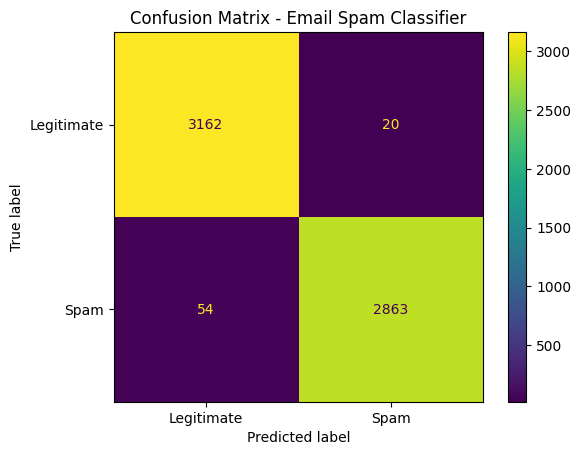

<Figure size 640x480 with 0 Axes>

In [41]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Legitimate", "Spam"]
)

plt.title("Confusion Matrix - Email Spam Classifier")
plt.show()

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 15. Classification of New Emails

The trained NLP pipeline can also classify previously unseen raw email text.

A new email must pass through the same stages used during training:

1. Text cleaning
2. Stop-word removal
3. Lemmatization
4. TF-IDF transformation
5. Model prediction

In [30]:
def predict_email(email_text):

    # Clean email
    cleaned = clean_text(email_text)

    # Apply NLP preprocessing
    processed = preprocess_text(cleaned)

    # Apply the trained TF-IDF vectorizer
    email_tfidf = tfidf.transform([processed])

    # Make prediction
    prediction = model.predict(email_tfidf)[0]

    # Return readable result
    if prediction == 1:
        return "Spam"
    else:
        return "Legitimate"

In [31]:
sample_email = """
Congratulations!

You have won a cash prize.
Click the link immediately to claim your reward.
"""

print(predict_email(sample_email))

Spam


In [32]:
sample_email = """
Hello John,

Please review the project document before tomorrow's meeting.

Regards,
David
"""

print(predict_email(sample_email))

Legitimate


## 16. Evaluation Using Progressively Larger Datasets

The NLP system is evaluated using progressively larger subsets of the Enron dataset.

The following dataset sizes are tested:

- 1,000 emails
- 5,000 emails
- 10,000 emails
- 20,000 emails
- Full dataset

For every experiment:

1. A stratified subset is selected.
2. The subset is divided into training and testing data.
3. A new TF-IDF vectorizer is trained.
4. A new Multinomial Naive Bayes classifier is trained.
5. Accuracy, precision, recall, and F1-score are calculated.

Each experiment is performed independently.

In [33]:
def run_dataset_size_experiments(
    df,
    sizes=[1000, 5000, 10000, 20000]
):

    results = []

    for size in sizes:

        # Select stratified dataset subset
        if size < len(df):

            subset, _ = train_test_split(
                df,
                train_size=size,
                random_state=42,
                stratify=df["label"]
            )

        else:
            subset = df.copy()

        # Define input and target
        X = subset["processed_email"]
        y = subset["label"]

        # Train/test split
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.20,
            random_state=42,
            stratify=y
        )

        # TF-IDF
        experiment_tfidf = TfidfVectorizer()

        X_train_tfidf = experiment_tfidf.fit_transform(X_train)
        X_test_tfidf = experiment_tfidf.transform(X_test)

        # Train model
        experiment_model = MultinomialNB()

        experiment_model.fit(
            X_train_tfidf,
            y_train
        )

        # Prediction
        y_pred = experiment_model.predict(
            X_test_tfidf
        )

        # Metrics
        accuracy = accuracy_score(
            y_test,
            y_pred
        )

        precision = precision_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        # Save results
        results.append({
            "Dataset Size": len(subset),
            "Training Size": len(X_train),
            "Test Size": len(X_test),
            "TF-IDF Features": X_train_tfidf.shape[1],
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1
        })

        print(
            f"Completed experiment with "
            f"{len(subset):,} emails"
        )

    return pd.DataFrame(results)

In [34]:
dataset_sizes = [
    1000,
    5000,
    10000,
    20000,
    len(df)
]

results_df = run_dataset_size_experiments(
    df,
    dataset_sizes
)

results_df

Completed experiment with 1,000 emails
Completed experiment with 5,000 emails
Completed experiment with 10,000 emails
Completed experiment with 20,000 emails
Completed experiment with 30,494 emails


,Dataset Size,Training Size,Test Size,TF-IDF Features,Accuracy,Precision,Recall,F1 Score
0,1000,800,200,17688,0.950000,0.952760,0.950000,0.949839
1,5000,4000,1000,46569,0.977000,0.977004,0.977000,0.977001
2,10000,8000,2000,65946,0.984000,0.984026,0.984000,0.983997
3,20000,16000,4000,95360,0.981500,0.981583,0.981500,0.981493
4,30494,24395,6099,119220,0.987867,0.987922,0.987867,0.987864


## 17. Experimental Results

The model was evaluated on progressively larger datasets to investigate how the amount of available data affected classification performance.

Overall, classification performance improved as the dataset increased.

The full dataset produced the strongest overall result.

## 18. Effect of Dataset Size on Accuracy

The following graph illustrates how classification accuracy changed as progressively larger datasets were used.

Although performance does not increase perfectly at every dataset size, the overall trend shows improved classification performance as more training data becomes available.

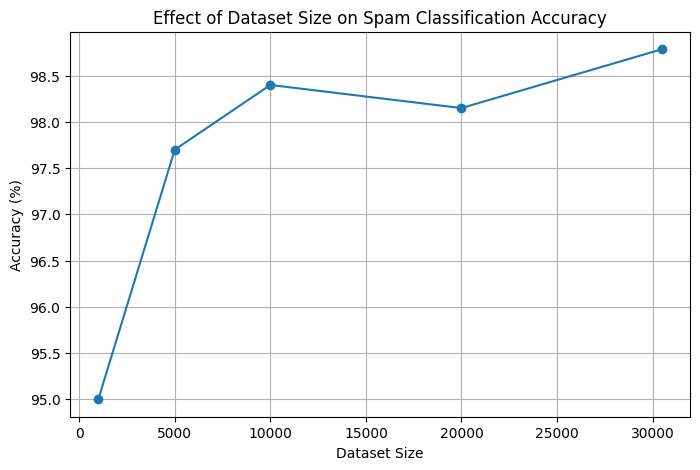

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Dataset Size"],
    results_df["Accuracy"] * 100,
    marker="o"
)

plt.xlabel("Dataset Size")
plt.ylabel("Accuracy (%)")

plt.title(
    "Effect of Dataset Size on "
    "Spam Classification Accuracy"
)

plt.grid(True)

plt.show()

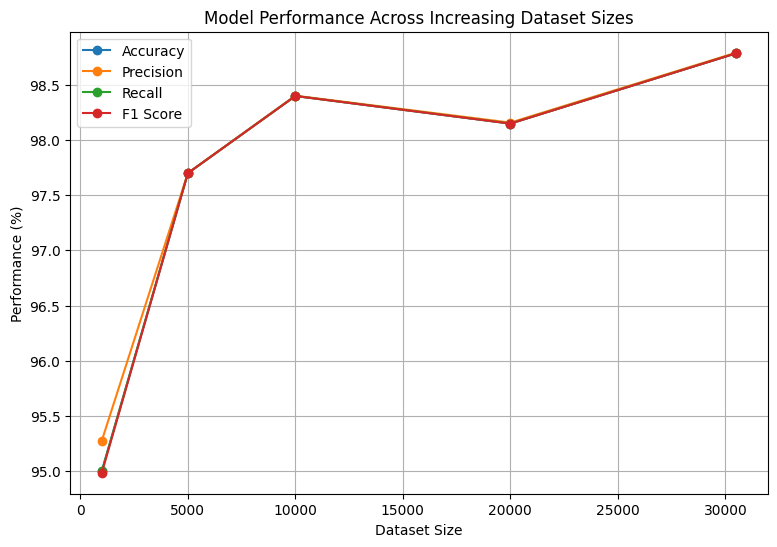

In [36]:
plt.figure(figsize=(9, 6))

plt.plot(
    results_df["Dataset Size"],
    results_df["Accuracy"] * 100,
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["Dataset Size"],
    results_df["Precision"] * 100,
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["Dataset Size"],
    results_df["Recall"] * 100,
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["Dataset Size"],
    results_df["F1 Score"] * 100,
    marker="o",
    label="F1 Score"
)

plt.xlabel("Dataset Size")
plt.ylabel("Performance (%)")

plt.title(
    "Model Performance Across "
    "Increasing Dataset Sizes"
)

plt.legend()
plt.grid(True)

plt.show()

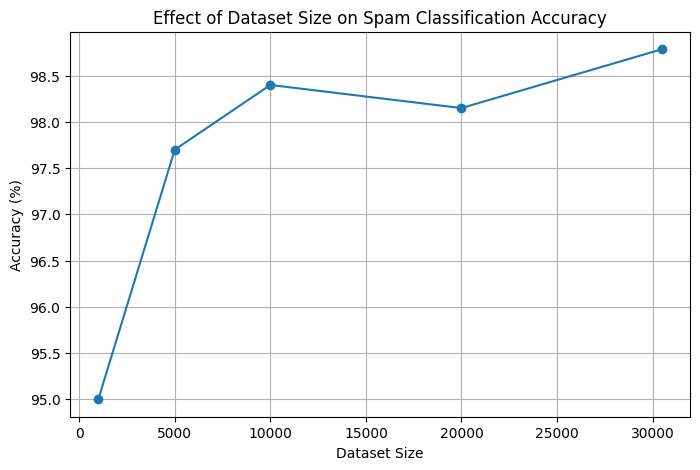

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Dataset Size"],
    results_df["Accuracy"] * 100,
    marker="o"
)

plt.xlabel("Dataset Size")
plt.ylabel("Accuracy (%)")
plt.title("Effect of Dataset Size on Spam Classification Accuracy")
plt.grid(True)

# Save the graph as an image file
plt.savefig(
    "dataset_size_vs_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 20. Save Experimental Results

The experimental results are exported as a CSV file so that they can be included with the project repository and referenced during report preparation.

In [37]:
results_df.to_csv(
    "dataset_size_experiment_results.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [38]:
import joblib

joblib.dump(
    model,
    "spam_classifier.pkl"
)

joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer saved.")

Model and TF-IDF vectorizer saved.


In [39]:
import joblib

joblib.dump(
    model,
    "spam_classifier.pkl"
)

joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)

print("Model and TF-IDF vectorizer saved.")

Model and TF-IDF vectorizer saved.


## 22. Conclusion

This project developed an NLP-based email spam classification system using the Enron Spam dataset.

The email text was cleaned and preprocessed using stop-word removal and lemmatization. TF-IDF was used to transform the processed email text into numerical features, and a Multinomial Naive Bayes classifier was trained to distinguish legitimate emails from spam.

Using the full dataset of 30,494 unique emails, the model achieved an accuracy of approximately 98.79% on the held-out test dataset.

The progressive dataset experiments also demonstrated that model performance generally improved as more data became available. Accuracy increased from 95.00% using 1,000 emails to 98.79% using the full dataset.

The results demonstrate that classical NLP preprocessing, TF-IDF feature extraction, and supervised machine learning can provide strong performance for binary email spam classification.